Cette démonstration reprend des éléments des exemples de scikit-learn sur [DBSCAN](https://scikit-learn.org/stable/auto_examples/cluster/plot_dbscan.html) et [HDBSCAN](https://scikit-learn.org/stable/auto_examples/cluster/plot_hdbscan.html).

In [1]:
%matplotlib inline

# Clustering DBSCAN

DBSCAN suit la densité des points. Il a deux réglages : une distance ε (`eps`) et un nombre minimum de voisins (`min_samples`, le *v* des diapositives, le point compris).

- **Point central** : au moins `min_samples` voisins dans son ε-voisinage ;
- **Point de bordure** : pas central, mais voisin d'un point central : il rejoint son cluster ;
- **Bruit** : ni l'un ni l'autre.

Un cluster s'étend de proche en proche entre points centraux voisins.

Les données sont celles de la figure « DBSCAN — Exemple » des diapositives : deux croissants entrelacés ([`make_moons`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html)) et 15 points tirés au hasard sur le plan. Des clusters qui ne sont pas ronds, et du bruit : ce que k-means ne sait pas traiter.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import DBSCAN, HDBSCAN, KMeans
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

# Deux croissants entrelacés, et 15 points tirés au hasard sur le plan
moons, moon_labels = make_moons(n_samples=300, noise=0.06, random_state=0)
rng = np.random.default_rng(0)
X = np.vstack([moons, rng.uniform((-1.3, -0.8), (2.3, 1.3), size=(15, 2))])


def count(labels):
  """Nombre de clusters et nombre de points de bruit (label -1)."""
  return len(set(labels) - {-1}), int(np.sum(labels == -1))


def show(ax, points, labels, title, core=None):
  """Points centraux pleins, de bordure creux, bruit en croix."""
  noise = labels == -1
  if core is None:
    core = ~noise
  border = ~core & ~noise
  ax.scatter(*points[core].T, s=12, c=labels[core], cmap="tab10", vmin=0, vmax=9)
  ax.scatter(
    *points[border].T,
    s=22,
    facecolors="white",
    edgecolors=plt.cm.tab10(labels[border]),
  )
  ax.scatter(*points[noise].T, s=25, marker="x", color="k")
  ax.set_title(title)
  ax.set_aspect("equal")
  ax.set_xticks([])
  ax.set_yticks([])

## K-means et DBSCAN côte à côte

K-means avec k = 2, DBSCAN avec ε = 0,2 et `min_samples=5` (le choix de ε vient dans la partie suivante). L'ARI compare les clusters aux deux croissants : 1 = partition identique, ≈ 0 = hasard.

DBSCAN : 2 clusters, 10 points de bruit
303 points centraux, 2 points de bordure
ARI sur les croissants : k-means 0.20, DBSCAN 1.00
Silhouette moyenne : k-means 0.48, DBSCAN 0.32 (sans le bruit)


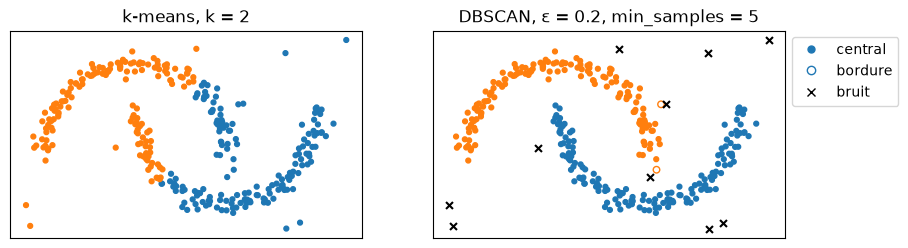

In [3]:
kmeans_labels = KMeans(n_clusters=2, random_state=0).fit_predict(X)
dbscan = DBSCAN(eps=0.2, min_samples=5).fit(X)
labels = dbscan.labels_
is_core = np.zeros(len(X), dtype=bool)
is_core[dbscan.core_sample_indices_] = True

is_border = ~is_core & (labels != -1)
n_clusters, n_noise = count(labels)
print(f"DBSCAN : {n_clusters} clusters, {n_noise} points de bruit")
print(f"{is_core.sum()} points centraux, {is_border.sum()} points de bordure")

# ARI sur les 300 points des croissants, comparés aux deux croissants
ari_kmeans = adjusted_rand_score(moon_labels, kmeans_labels[:300])
ari_dbscan = adjusted_rand_score(moon_labels, labels[:300])
print(f"ARI sur les croissants : k-means {ari_kmeans:.2f}, DBSCAN {ari_dbscan:.2f}")
kept = labels != -1
silhouette_kmeans = silhouette_score(X, kmeans_labels)
silhouette_dbscan = silhouette_score(X[kept], labels[kept])
print(f"Silhouette moyenne : k-means {silhouette_kmeans:.2f}, ", end="")
print(f"DBSCAN {silhouette_dbscan:.2f} (sans le bruit)")

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.5))
show(left, X, kmeans_labels, "k-means, k = 2")
show(right, X, labels, "DBSCAN, ε = 0.2, min_samples = 5", core=is_core)
right.legend(
  handles=[
    plt.Line2D([], [], marker="o", ls="", color="C0", markersize=5, label="central"),
    plt.Line2D(
      [], [], marker="o", ls="", mfc="white", mec="C0", markersize=6, label="bordure"
    ),
    plt.Line2D([], [], marker="x", ls="", color="k", label="bruit"),
  ],
  loc="upper left",
  bbox_to_anchor=(1, 1),
)
plt.show()

K-means coupe les croissants en deux moitiés (ARI 0,20) : il cherche des groupes ronds autour de centroïdes, et chaque frontière est à égale distance de deux centroïdes. DBSCAN suit la densité : il retrouve les deux croissants (ARI 1,00) et met en bruit 10 des 15 points ajoutés (les 5 autres sont tombés sur un croissant).

La silhouette moyenne préfère pourtant k-means (0,48 contre 0,32) : elle favorise les clusters ronds et compacts. C'est un indice parmi d'autres.

## Choisir ε : la courbe des k-distances

Pour chaque point, la distance à son 5e voisin (5 = `min_samples`, le point compté parmi ses voisins comme dans DBSCAN), triée. Dans les zones denses, cette distance est petite ; pour le bruit, elle est grande. On prend ε au coude, là où la courbe se redresse.

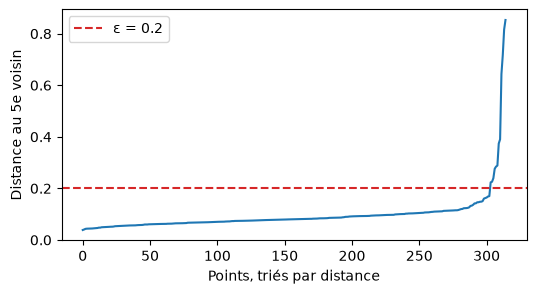

In [4]:
# Distance de chaque point à son 5e voisin, lui compris (comme min_samples)
neighbors = NearestNeighbors(n_neighbors=5).fit(X)
distances = np.sort(neighbors.kneighbors(X)[0][:, -1])

plt.figure(figsize=(6, 3))
plt.plot(distances)
plt.axhline(0.2, color="C3", ls="--", label="ε = 0.2")
plt.xlabel("Points, triés par distance")
plt.ylabel("Distance au 5e voisin")
plt.legend()
plt.show()

Trois valeurs de ε autour du coude :

ε = 0.1 : 11 cluster(s), 29 points de bruit
ε = 0.2 : 2 cluster(s), 10 points de bruit
ε = 0.3 : 1 cluster(s), 6 points de bruit


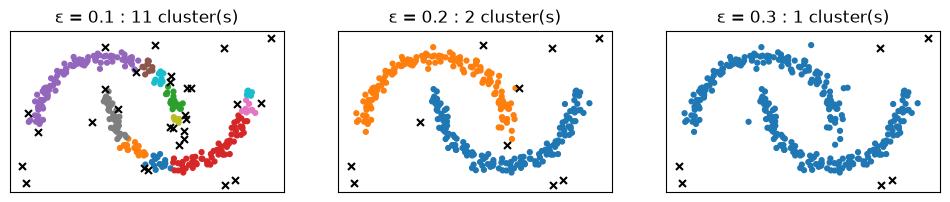

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, eps in zip(axes, (0.1, 0.2, 0.3)):
  labels = DBSCAN(eps=eps, min_samples=5).fit(X).labels_
  n_clusters, n_noise = count(labels)
  print(f"ε = {eps} : {n_clusters} cluster(s), {n_noise} points de bruit")
  show(ax, X, labels, f"ε = {eps} : {n_clusters} cluster(s)")
plt.show()

ε trop petit (0,1) : les croissants se morcellent en 11 clusters, avec 29 points de bruit. ε trop grand (0,3) : les deux croissants se rejoignent en un seul cluster. Au coude, ε = 0,2 les sépare.

## HDBSCAN

[HDBSCAN](https://scikit-learn.org/stable/modules/clustering.html#hdbscan) (`sklearn.cluster.HDBSCAN`, scikit-learn ≥ 1.3), c'est DBSCAN sur toutes les valeurs de ε : il garde les clusters qui durent le plus longtemps quand ε varie. Plus de ε à régler, des densités variables, et un seul réglage : la taille minimale d'un cluster (`min_cluster_size`).

Sur les croissants, sans ε :

In [6]:
# copy=True : HDBSCAN ne modifie pas X (le défaut à partir de scikit-learn 1.10)
labels = HDBSCAN(min_cluster_size=10, copy=True).fit(X).labels_
n_clusters, n_noise = count(labels)
print(f"HDBSCAN : {n_clusters} clusters, {n_noise} points de bruit, ", end="")
print(f"ARI sur les croissants {adjusted_rand_score(moon_labels, labels[:300]):.2f}")

HDBSCAN : 2 clusters, 11 points de bruit, ARI sur les croissants 0.99


Sur trois groupes de densités différentes (ceux de l'exemple HDBSCAN de scikit-learn), un seul ε ne convient pas à tous les clusters :

DBSCAN, ε = 0.2 : 6 clusters, 83 points de bruit, ARI 0.76
DBSCAN, ε = 0.5 : 2 clusters, 3 points de bruit, ARI 0.56
HDBSCAN, min_cluster_size = 20 : 3 clusters, 78 points de bruit, ARI 0.85


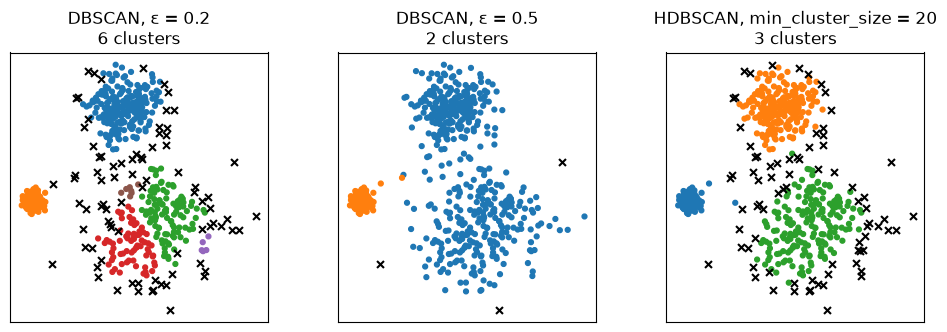

In [7]:
blobs, blob_labels = make_blobs(
  n_samples=750,
  centers=[[1, 1], [-1, -1], [1.5, -1.5]],
  cluster_std=[0.4, 0.1, 0.75],
  random_state=0,
)
models = {
  "DBSCAN, ε = 0.2": DBSCAN(eps=0.2, min_samples=5),
  "DBSCAN, ε = 0.5": DBSCAN(eps=0.5, min_samples=5),
  "HDBSCAN, min_cluster_size = 20": HDBSCAN(min_cluster_size=20, copy=True),
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (title, model) in zip(axes, models.items()):
  labels = model.fit(blobs).labels_
  n_clusters, n_noise = count(labels)
  ari = adjusted_rand_score(blob_labels, labels)
  print(f"{title} : {n_clusters} clusters, {n_noise} points de bruit, ARI {ari:.2f}")
  show(ax, blobs, labels, f"{title}\n{n_clusters} clusters")
plt.show()

In [8]:
for size in (10, 40):
  labels = HDBSCAN(min_cluster_size=size, copy=True).fit(blobs).labels_
  n_clusters, n_noise = count(labels)
  print(
    f"HDBSCAN, min_cluster_size = {size} : {n_clusters} clusters, {n_noise} points de bruit"
  )

HDBSCAN, min_cluster_size = 10 : 3 clusters, 48 points de bruit
HDBSCAN, min_cluster_size = 40 : 3 clusters, 101 points de bruit


Avec ε = 0,2, le groupe le moins dense se morcelle (6 clusters, 83 points de bruit) ; avec ε = 0,5, les deux groupes de droite fusionnent (2 clusters). HDBSCAN trouve les 3 groupes, et les garde pour une taille minimale de 10 à 40 : un réglage peu sensible. Il range en bruit les points épars du groupe le moins dense, ce qui fait baisser son ARI.